# 03 · Modelos de Clasificación — ¿Será un hit?

**Pregunta de negocio:** dada una canción (su género y características de audio), ¿llegará al ~25% más popular del catálogo?

- **Target:** `is_hit` = 1 si `popularity >= 50` (26.6% de las canciones)
- **Pipelines Kedro:** `modeling` (entrenamiento), `hyperparameter_tuning` (RandomizedSearchCV), `evaluation` (métricas)

> Este notebook **no reentrena**: carga los modelos y resultados que generó `kedro run`. Para reproducir todo desde cero:
> ```
> kedro run
> ```

### Modelos y justificación

| Modelo | Por qué | Configuración clave |
|---|---|---|
| **Baseline** (DummyClassifier) | Piso de referencia: siempre predice "no hit" | `strategy=most_frequent` |
| **Logistic Regression** | Lineal e interpretable: sus coeficientes muestran la dirección del efecto de cada variable | `C=1.0`, L2, `class_weight=balanced` |
| **Random Forest** | Captura relaciones no lineales (el EDA mostró correlaciones lineales < 0.1 con popularity) | 200 árboles, `max_depth=20`, `min_samples_leaf=5`, `class_weight=balanced` |
| **Gradient Boosting** (HistGradientBoosting) | Árboles secuenciales que corrigen errores del anterior; el estado del arte en datos tabulares | Ajustado con RandomizedSearchCV (15 combinaciones × 3 folds, optimizando F1) |

`class_weight=balanced` compensa el desbalance de clases dando más peso a los errores sobre los hits.

### Métrica principal: F1

Con 73% de "no hits", un modelo que nunca predice hit logra **73% de Accuracy** sin servir para nada. Por eso se prioriza **F1** (equilibrio entre Precision y Recall) y **ROC-AUC** (capacidad de ordenar canciones por probabilidad de hit).

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 120)

PLOTS = "../results/plots"
params = catalog.load("parameters")

                    INFO     Loading data from parameters (MemoryDataset)...                   ]8;id=10051546;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051547;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

## 1. Optimización de hiperparámetros — Gradient Boosting

RandomizedSearchCV prueba 15 combinaciones aleatorias del espacio de búsqueda (vs. 432 de un GridSearch completo) con validación cruzada de 3 folds.

In [3]:
hp = catalog.load("hyperparameter_results_clf")
hp.head(5)

                    INFO     Loading data from hyperparameter_results_clf (CSVDataset)...      ]8;id=10051552;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051553;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
0,1,0.670753,0.003568,6.898263,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0}"
1,2,0.670705,0.002036,9.870912,"{'min_samples_leaf': 20, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}"
2,3,0.669991,0.001349,9.631289,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}"
3,4,0.669479,0.003514,6.440829,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.0}"
4,5,0.668233,0.001399,8.369599,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.0}"


In [4]:
gb = catalog.load("gradient_boosting_clf")
{k: v for k, v in gb.get_params().items()
 if k in ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "class_weight"]}

                    INFO     Loading data from gradient_boosting_clf (PickleDataset)...        ]8;id=10051558;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051559;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\


{
    'class_weight': 'balanced',
    'l2_regularization': 1.0,
    'learning_rate': 0.05,
    'max_iter': 200,
    'max_leaf_nodes': 127,
    'min_samples_leaf': 50
}

Las mejores combinaciones usan árboles con muchas hojas (`max_leaf_nodes=127`) y `min_samples_leaf=50`: el modelo necesita complejidad para capturar las interacciones género × audio, pero con hojas grandes para no sobreajustar. Las 5 mejores combinaciones tienen F1 entre 0.668 y 0.671: el modelo es **robusto** a la elección exacta de hiperparámetros.

## 2. Métricas en test

In [5]:
clf_metrics = catalog.load("clf_test_metrics")
clf_metrics.style.highlight_max(subset=["Accuracy", "Precision", "F1", "ROC_AUC"], color="#C8F7C5").format(precision=4)

                    INFO     Loading data from clf_test_metrics (CSVDataset)...                ]8;id=10051564;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051565;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Baseline,0.7344,0.0000,0.0000,0.0000,0.5000
1,LogisticRegression,0.7637,0.5364,0.8126,0.6462,0.8611
2,RandomForest,0.7214,0.4856,0.8323,0.6134,0.8458
3,GradientBoosting,0.7964,0.5837,0.8131,0.6796,0.8844


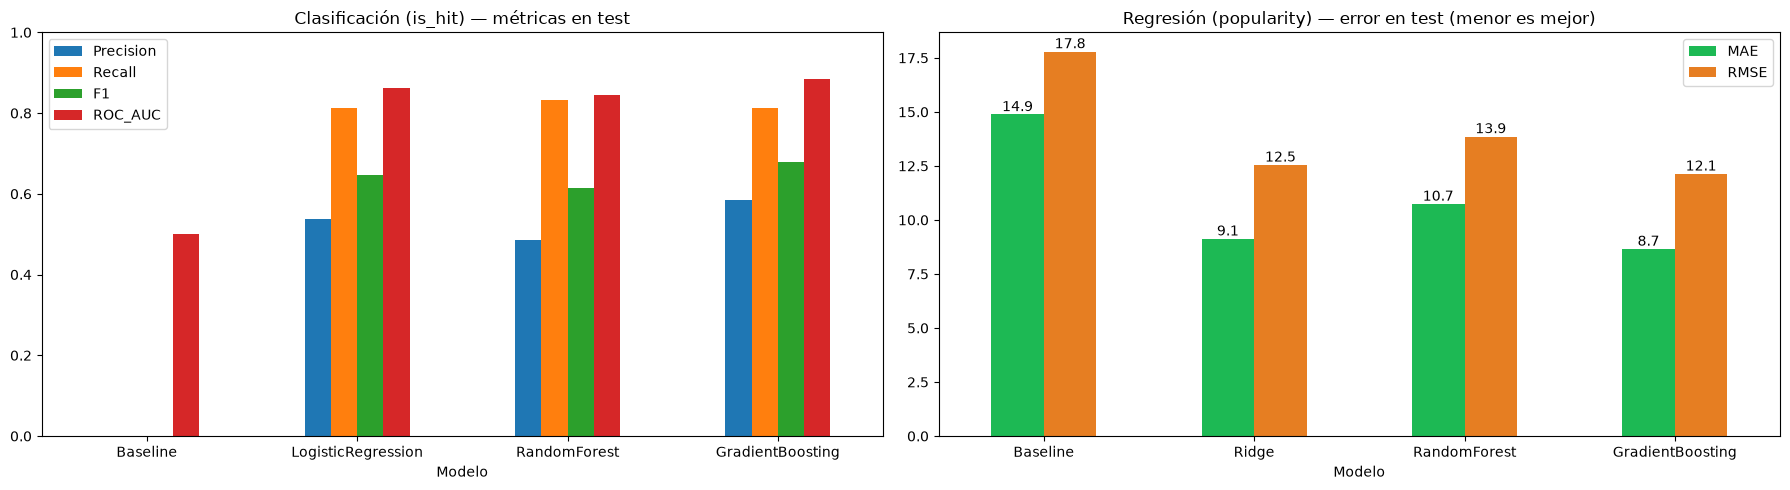

In [6]:
display(Image(f"{PLOTS}/04_metrics_comparison.png"))

**Interpretación:**

- El **Baseline** confirma la trampa del Accuracy: 73.4% sin detectar ningún hit (F1 = 0).
- **Gradient Boosting es el mejor modelo** en F1 (0.680), Accuracy (79.6%), Precision (58.4%) y ROC-AUC (0.884).
- **Logistic Regression** queda muy cerca (F1 0.646, AUC 0.861) siendo un modelo lineal: buena parte de la señal es aditiva (principalmente el género).
- **Random Forest** tiene el mayor Recall (83%) pero la peor Precision (48.6%): marca demasiadas canciones como hit. Con `max_depth=20` y `class_weight=balanced` queda sesgado hacia la clase positiva.

## 3. Validación cruzada (5 folds sobre train)

Confirma que el resultado en test no depende de un split afortunado.

In [7]:
cv = catalog.load("cv_clf_results")
cv

                    INFO     Loading data from cv_clf_results (CSVDataset)...                  ]8;id=10051570;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051571;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,f1_mean,f1_std,recall_mean,recall_std,precision_mean,precision_std,roc_auc_mean,roc_auc_std
0,LogisticRegression,0.6433,0.0028,0.8072,0.0049,0.5348,0.0029,0.8580,0.0022
1,RandomForest,0.6105,0.0052,0.8207,0.0077,0.4860,0.0056,0.8401,0.0028
2,GradientBoosting,0.6728,0.0038,0.7980,0.0084,0.5815,0.0054,0.8778,0.0020


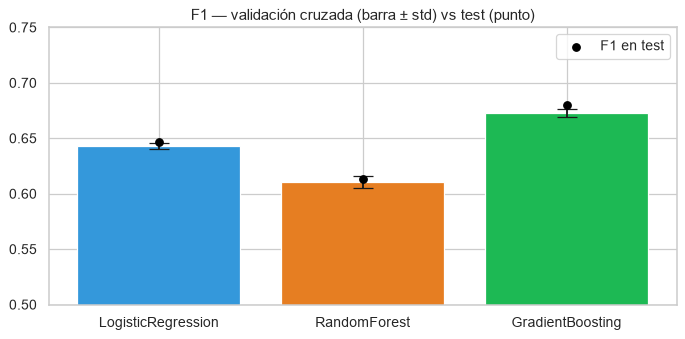

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cv["Modelo"], cv["f1_mean"], yerr=cv["f1_std"], capsize=8, color=["#3498DB", "#E67E22", "#1DB954"])
ax.scatter(clf_metrics["Modelo"].iloc[1:], clf_metrics["F1"].iloc[1:], color="black", zorder=3, label="F1 en test")
ax.set_ylim(0.5, 0.75)
ax.set_title("F1 — validación cruzada (barra ± std) vs test (punto)")
ax.legend()
plt.show()

Las desviaciones estándar entre folds son muy bajas (< 0.006) y el F1 en test coincide con el de CV: **los modelos son estables y no hay sobreajuste**. El ranking (GB > LR > RF) se mantiene en ambos.

## 4. Matrices de confusión y curvas ROC

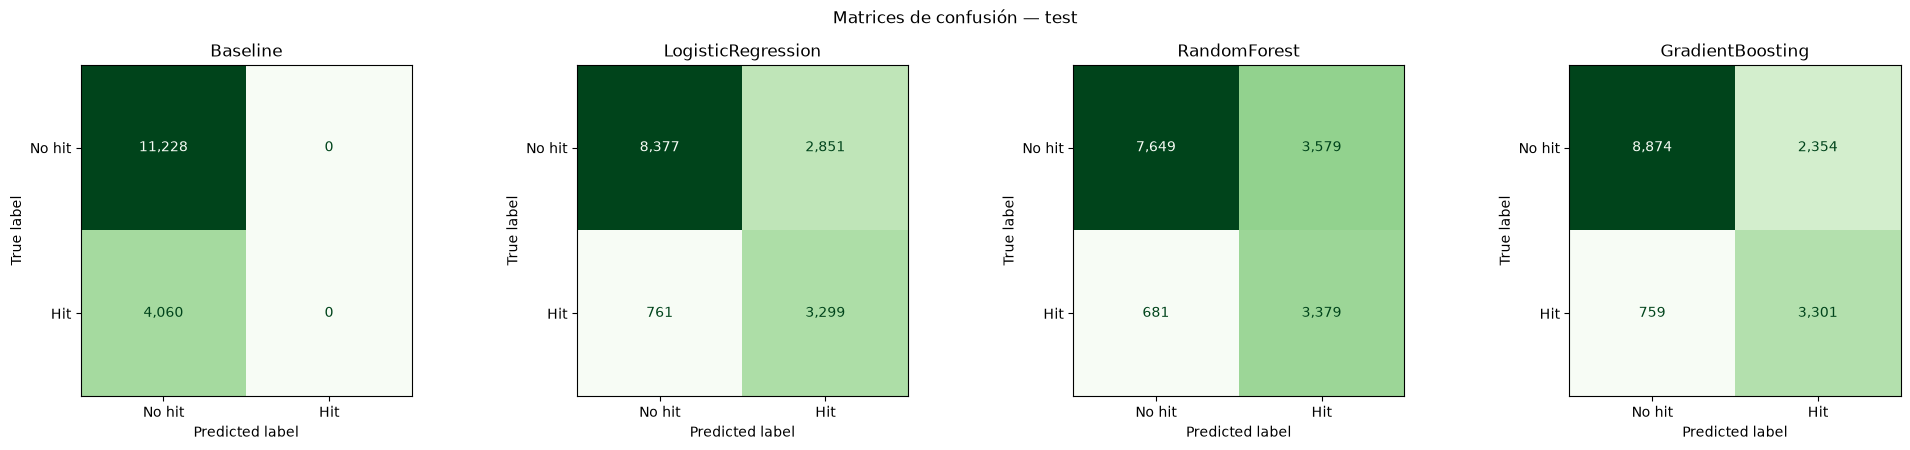

In [9]:
display(Image(f"{PLOTS}/03_clf_confusion_matrices.png"))

Sobre 15.288 canciones de test (4.060 hits reales), Gradient Boosting:

- Detecta **3.301 de 4.060 hits** (Recall 81%).
- Genera **2.354 falsos positivos**, ~500 menos que Logistic Regression y ~1.200 menos que Random Forest.
- Deja escapar 759 hits (falsos negativos).

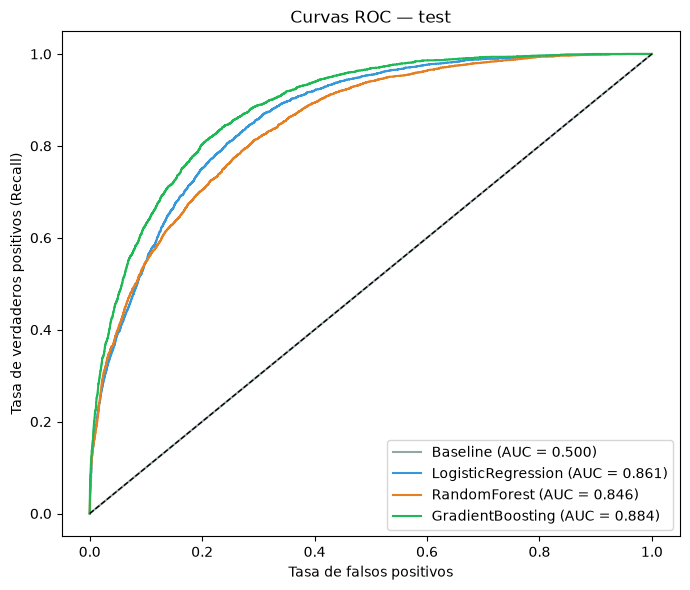

In [10]:
display(Image(f"{PLOTS}/03_clf_roc_curves.png"))

Un AUC de 0.884 significa que, si se toma un hit y un no-hit al azar, el modelo le asigna mayor probabilidad al hit el 88% de las veces.

## 5. Análisis de umbral — traducción a negocio

El umbral por defecto (0.5) maximiza Recall. Pero un sello o una plataforma tiene **presupuesto limitado de promoción**: lo relevante es *si promociono las N canciones con mayor probabilidad según el modelo, ¿cuántas son realmente hits?*

In [11]:
X_test = catalog.load("X_test")
y_test = catalog.load("y_test_clf").squeeze()
proba = gb.predict_proba(X_test)[:, 1]
tasa_base = y_test.mean()

filas = []
for top in [0.05, 0.10, 0.20, 0.30]:
    sel = proba >= np.quantile(proba, 1 - top)
    filas.append({
        "Promocionar top": f"{top:.0%}",
        "Canciones": int(sel.sum()),
        "% que son hits (Precision)": y_test[sel].mean(),
        "Lift vs azar": y_test[sel].mean() / tasa_base,
        "% de todos los hits capturados": y_test[sel].sum() / y_test.sum(),
    })
lift = pd.DataFrame(filas)
print(f"Elegir al azar: {tasa_base:.1%} de hits")
lift.style.format({"% que son hits (Precision)": "{:.1%}", "Lift vs azar": "{:.2f}x", "% de todos los hits capturados": "{:.1%}"})

[10/19/26 23:04:17] INFO     Loading data from X_test (CSVDataset)...                          ]8;id=10051576;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051577;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from y_test_clf (CSVDataset)...                      ]8;id=10051582;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051583;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

Elegir al azar: 26.6% de hits


,Promocionar top,Canciones,% que son hits (Precision),Lift vs azar,% de todos los hits capturados
0,5%,765,91.0%,3.43x,17.1%
1,10%,1529,85.0%,3.20x,32.0%
2,20%,3058,73.9%,2.78x,55.7%
3,30%,4587,63.7%,2.40x,72.0%


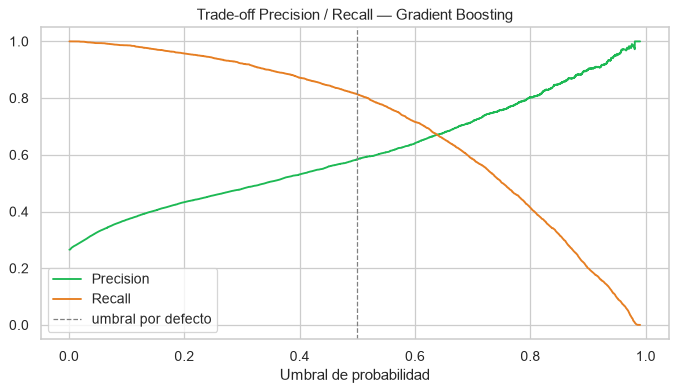

In [12]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr, prec[:-1], label="Precision", color="#1DB954")
ax.plot(thr, rec[:-1], label="Recall", color="#E67E22")
ax.axvline(0.5, color="gray", ls="--", lw=1, label="umbral por defecto")
ax.set_xlabel("Umbral de probabilidad")
ax.set_title("Trade-off Precision / Recall — Gradient Boosting")
ax.legend()
plt.show()

**Lectura de negocio:** si se promociona solo el **10%** de canciones con mayor probabilidad, el **85% son hits reales** (lift de 3.2x frente a elegir al azar, donde solo el 26.6% lo son). El umbral se ajusta según el objetivo:

- **Presupuesto acotado** (playlists editoriales, campañas pagadas) → umbral alto, priorizar Precision.
- **Descubrimiento amplio** (no dejar pasar ningún potencial hit) → umbral 0.5, priorizar Recall.

## 6. ¿Qué hace que una canción sea un hit?

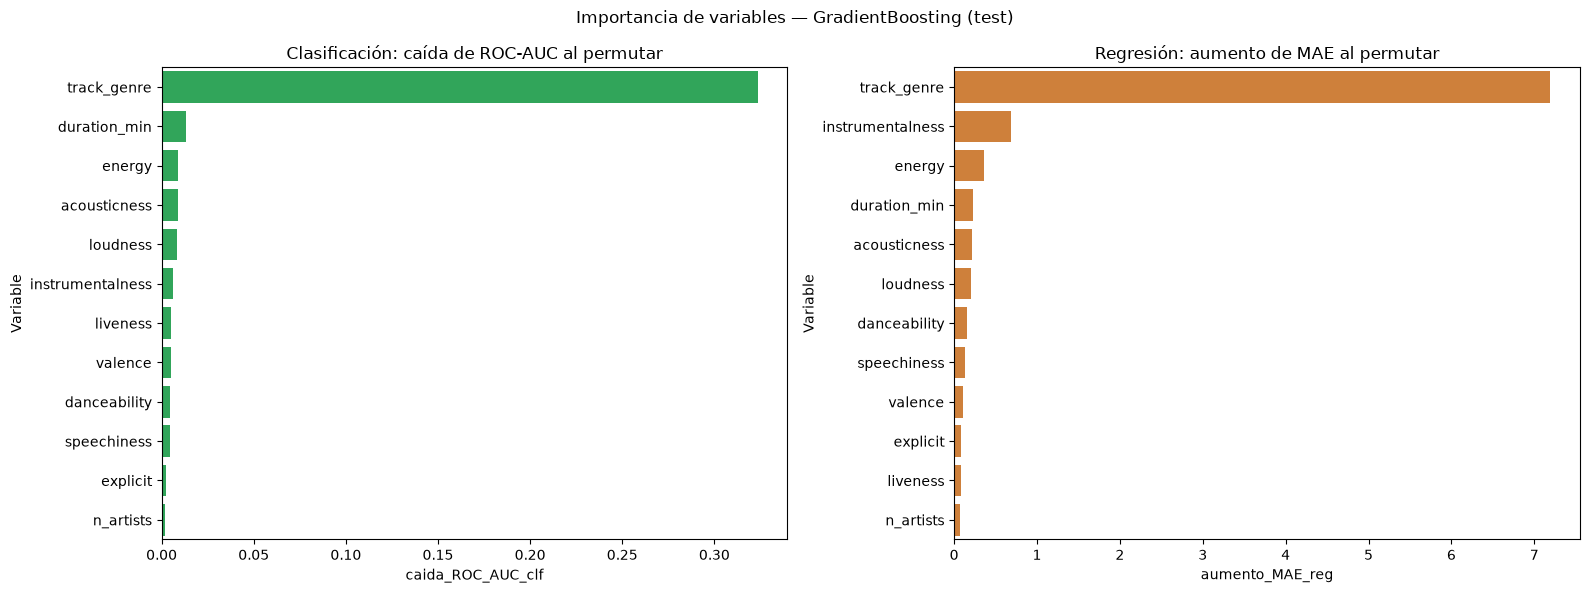

In [13]:
display(Image(f"{PLOTS}/04_feature_importance.png"))

In [14]:
catalog.load("feature_importance").head(10)

                    INFO     Loading data from feature_importance (CSVDataset)...              ]8;id=10051588;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=10051589;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Variable,caida_ROC_AUC_clf,aumento_MAE_reg
0,track_genre,0.3235,7.1917
1,duration_min,0.0132,0.2286
2,energy,0.0090,0.3581
3,acousticness,0.0087,0.2104
4,loudness,0.0085,0.1986
5,instrumentalness,0.0062,0.6873
6,liveness,0.0053,0.0826
7,valence,0.0053,0.1114
8,danceability,0.0047,0.1510
9,speechiness,0.0045,0.1368


La importancia por permutación (desordenar una variable y medir cuánto empeora el modelo) es contundente: **el género explica casi todo**. Permutarlo hace caer el ROC-AUC en 0.32 (de 0.88 a ~0.56, casi azar); la siguiente variable (`duration_min`) solo lo baja 0.013.

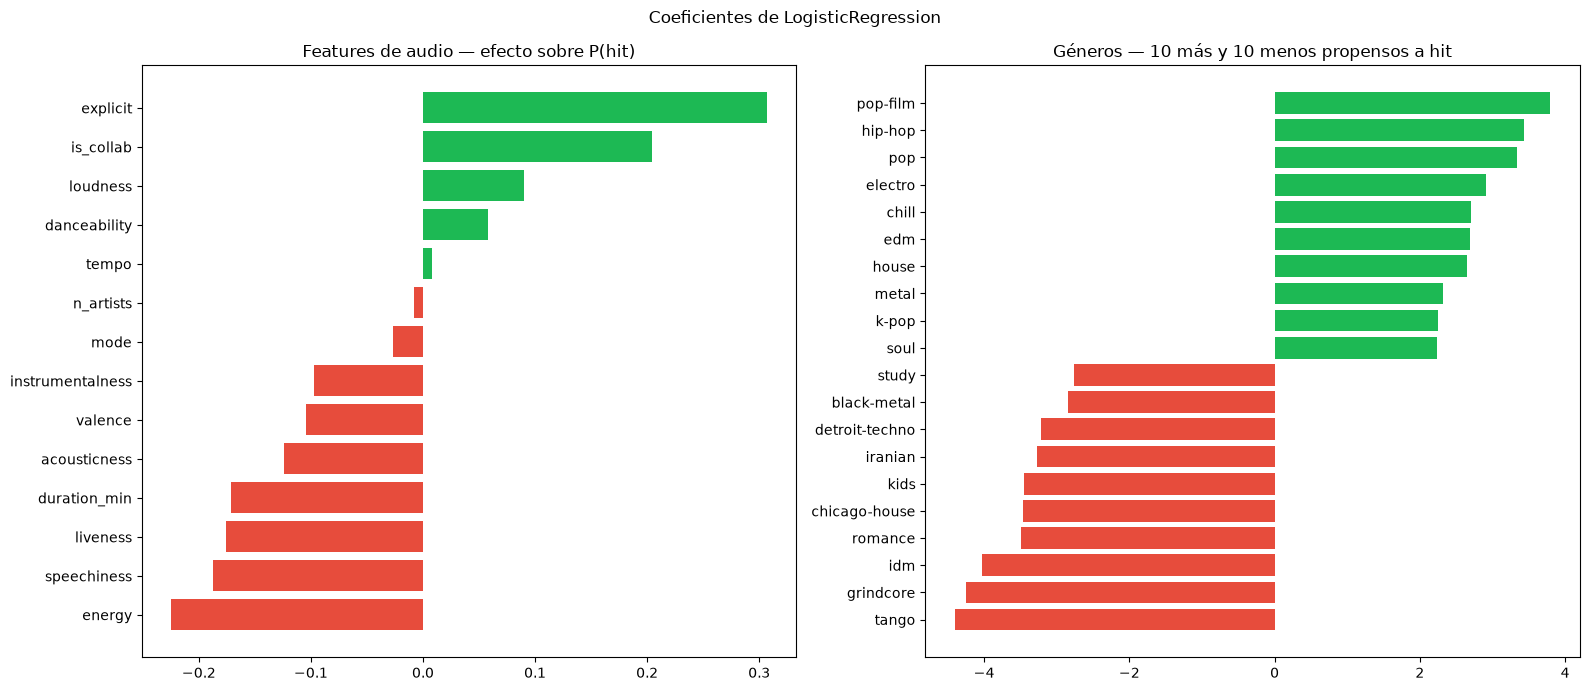

In [15]:
display(Image(f"{PLOTS}/03_clf_logistic_coefficients.png"))

Los coeficientes de Logistic Regression dan la **dirección** del efecto:

- **Géneros propensos a hit:** pop-film, hip-hop, pop, electro, chill, EDM, house, k-pop.
- **Géneros de nicho:** tango, grindcore, IDM, romance, chicago-house, kids, iranian.
- **Audio** (efectos pequeños): ser explícita (+), colaboración (+) y mayor volumen (+) suben la probabilidad; más energía, más voz hablada, grabaciones en vivo y mayor duración la bajan (manteniendo el género fijo).

## Conclusiones

1. **Gradient Boosting** es el modelo recomendado: F1 = 0.68, ROC-AUC = 0.88, estable en validación cruzada.
2. Supera ampliamente al baseline y permite **triplicar la tasa de acierto** al seleccionar canciones a promocionar.
3. La popularidad depende principalmente del **género** (mercado/audiencia), más que del sonido de la canción.
4. **Limitación:** el dataset tiene exactamente 1.000 canciones por género, por lo que la popularidad por género refleja cómo se construyó la muestra. No incluye variables clave como seguidores del artista, marketing o fecha de lanzamiento.